# S6E10✈️ | Orange blend

## Sources

| Prediction | Version | Public AUC | Weight |
|:--|--:|--:|--:|
| [Single Models](https://www.kaggle.com/code/ou20040313/s6e10-single-models?scriptVersionId=354361060) | 3 | 0.96061 | 10% |
| [Twin Stacks + Family Reg — goodpjw2008](https://www.kaggle.com/code/goodpjw2008/s6e10-twin-stacks-family-reg-lb-0-96187?scriptVersionId=357594210) | 8 | 0.96187 | 90% |

The public input is tied for the highest verified Public Score on the competition Code page on October 12. Its saved V8 submission averages the percentile ranks of two frozen stacks: goodpjw2008's 245-member stack and Dariush Afshar's 247-member stack. The file scores 0.96187; the family-regularized alternative is a separate output.

Single Models Version 5 contains a byte-for-byte copy of the Version 3 champion, checked by SHA-256. Its probabilities are converted to percentile ranks to match the public input's scale. The 90/10 weights are unchanged; this blend has no joint out-of-fold validation.


In [1]:
from pathlib import Path
import hashlib
import json

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ID, TARGET = "id", "satisfaction"
OWN_WEIGHT = 0.10
PUBLIC_WEIGHT = 1.0 - OWN_WEIGHT
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})


## Inputs

In [2]:
own_path = Path(kagglehub.notebook_output_download(
    "ou20040313/s6e10-single-models/versions/5", path="submission_best.csv"
))
public_path = Path(kagglehub.notebook_output_download(
    "goodpjw2008/s6e10-twin-stacks-family-reg-lb-0-96187/versions/8", path="submission.csv"
))
assert hashlib.sha256(own_path.read_bytes()).hexdigest() == "cb1e8978b036626a3b51396fb719396573a04932cbc8abc4868481e1a83d7449"
sample_paths = [p for p in Path("/kaggle/input").rglob("sample_submission.csv")
                if "playground-series-s6e10" in str(p)]
assert len(sample_paths) == 1, sample_paths
sample = pd.read_csv(sample_paths[0])
assert list(sample.columns) == [ID, TARGET]
assert len(sample) == 299_844 and sample[ID].is_unique and sample[ID].notna().all()
print("Own input:", own_path)
print("Public input:", public_path)
print(f"Test rows: {len(sample):,}")


Own input: /kaggle/input/notebooks/ou20040313/s6e10-single-models/submission_best.csv
Public input: /kaggle/input/notebooks/goodpjw2008/s6e10-twin-stacks-family-reg-lb-0-96187/submission.csv
Test rows: 299,844


## Alignment

In [3]:
def aligned_prediction(path):
    frame = pd.read_csv(path)
    assert list(frame.columns) == [ID, TARGET], (path, frame.columns.tolist())
    assert len(frame) == len(sample), (path, len(frame))
    assert frame[ID].is_unique and frame[ID].notna().all(), path
    assert set(frame[ID]) == set(sample[ID]), path
    aligned = sample[[ID]].merge(frame, on=ID, how="left", validate="one_to_one", sort=False)
    assert aligned[ID].equals(sample[ID])
    prediction = pd.to_numeric(aligned[TARGET], errors="raise").to_numpy(dtype=np.float64)
    assert np.isfinite(prediction).all(), path
    assert ((prediction >= 0) & (prediction <= 1)).all(), path
    return prediction

own_probability = aligned_prediction(own_path)
own = pd.Series(own_probability).rank(method="average", pct=True).to_numpy(dtype=np.float64)
public = aligned_prediction(public_path)
predictions = pd.DataFrame({"Single Models rank": own, "Twin Stacks rank": public})
display(predictions.describe(percentiles=[.01, .10, .50, .90, .99]).T)
print("Both inputs passed the ID, row-count and score checks.")


,count,mean,std,min,1%,10%,50%,90%,99%,max
Single Models rank,299844.0,0.500002,0.288676,0.000003,0.010003,0.100003,0.500002,0.900000,0.990000,1.000000
Twin Stacks rank,299844.0,0.500002,0.288669,0.000005,0.010029,0.100120,0.499993,0.899982,0.989999,0.999997


Both inputs passed the ID, row-count and score checks.


## Prediction Agreement

,value
Pearson correlation,0.978287
Spearman correlation,0.978284
Mean absolute difference,0.039686
95th percentile absolute difference,0.126990
Opposite sides of rank 0.5,0.012700


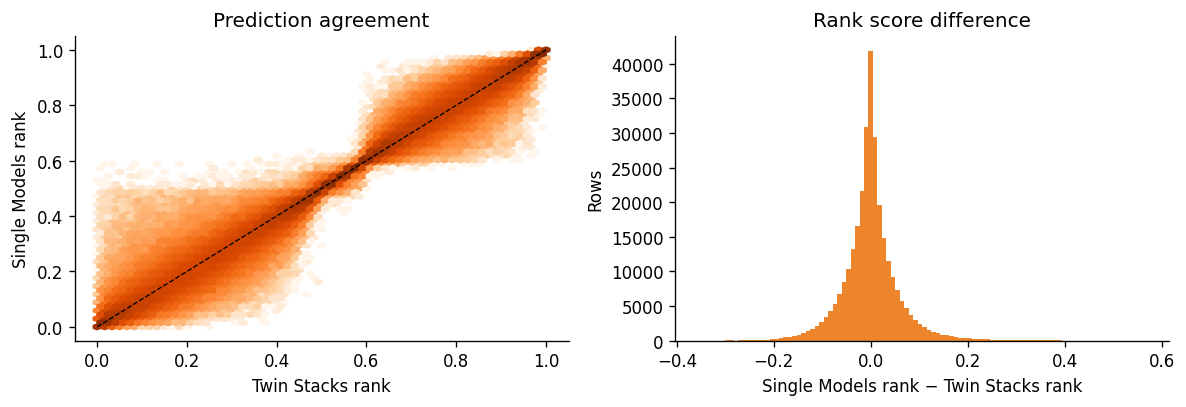

In [4]:
agreement = pd.Series({
    "Pearson correlation": predictions.corr(method="pearson").iloc[0, 1],
    "Spearman correlation": predictions.corr(method="spearman").iloc[0, 1],
    "Mean absolute difference": np.mean(np.abs(own - public)),
    "95th percentile absolute difference": np.quantile(np.abs(own - public), .95),
    "Opposite sides of rank 0.5": np.mean((own >= .5) != (public >= .5)),
}, name="value")
display(agreement.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hexbin(public, own, gridsize=60, bins="log", mincnt=1, cmap="Oranges")
axes[0].plot([0, 1], [0, 1], color="black", linewidth=.8, linestyle="--")
axes[0].set(xlabel="Twin Stacks rank", ylabel="Single Models rank", title="Prediction agreement")
axes[1].hist(own - public, bins=100, color="#ed852d")
axes[1].set(xlabel="Single Models rank − Twin Stacks rank", ylabel="Rows", title="Rank score difference")
fig.tight_layout()
plt.show()

## Blend

The public submission already contains rank scores. Ranking Single Models on the same test rows keeps both inputs on a common scale. Correlation describes agreement, not the expected leaderboard gain.


In [5]:
blend = OWN_WEIGHT * own + PUBLIC_WEIGHT * public
assert OWN_WEIGHT > 0 and PUBLIC_WEIGHT > 0
assert np.isclose(OWN_WEIGHT + PUBLIC_WEIGHT, 1.0)
assert np.isfinite(blend).all() and ((blend >= 0) & (blend <= 1)).all()
display(pd.DataFrame({"prediction": ["Single Models rank", "Twin Stacks rank"],
                      "weight": [OWN_WEIGHT, PUBLIC_WEIGHT]}))
print(f"Mean change from Twin Stacks rank: {np.mean(np.abs(blend - public)):.8f}")


,prediction,weight
0,Single Models rank,0.1
1,Twin Stacks rank,0.9


Mean change from Twin Stacks rank: 0.00396863


## Submission

In [6]:
submission = sample[[ID]].copy()
submission[TARGET] = blend
assert submission[ID].equals(sample[ID])
assert submission.shape == sample.shape and not submission.isna().any().any()
submission.to_csv("submission.csv", index=False, float_format="%.17g")

roundtrip = pd.read_csv("submission.csv")
assert roundtrip[ID].equals(sample[ID])
assert np.allclose(roundtrip[TARGET], blend, rtol=1e-14, atol=1e-15)

manifest = {
    "competition": "playground-series-s6e10",
    "method": "90/10 weighted rank score average",
    "rows": len(submission),
    "sources": [
        {"notebook": "ou20040313/s6e10-single-models", "version": 3,
         "script_version_id": 354361060, "input_version": 5, "file": own_path.name,
         "original_submission_file": "submission_features.csv",
         "public_auc": 0.96061, "weight": OWN_WEIGHT,
         "transform": "percentile rank (average ties)",
         "sha256": hashlib.sha256(own_path.read_bytes()).hexdigest()},
        {"notebook": "goodpjw2008/s6e10-twin-stacks-family-reg-lb-0-96187", "version": 8,
         "script_version_id": 357594210, "file": public_path.name,
         "public_auc": 0.96187, "weight": PUBLIC_WEIGHT,
         "transform": "saved twin rank average",
         "sha256": hashlib.sha256(public_path.read_bytes()).hexdigest()},
    ],
    "submission_sha256": hashlib.sha256(Path("submission.csv").read_bytes()).hexdigest(),
}
Path("blend_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
print(f"Saved submission.csv: {len(submission):,} rows")
print("SHA-256:", manifest["submission_sha256"])
display(submission.head())


Saved submission.csv: 299,844 rows
SHA-256: 627182265e34113237cd57b7788f4e33cf5ed06c70115dfc70c6dece835d5bf1


,id,satisfaction
0,699635,0.526461
1,699636,0.587823
2,699637,0.650167
3,699638,0.459933
4,699639,0.336550


## Results

| Prediction | Public AUC |
|:--|--:|
| Single Models champion | 0.96061 |
| Previous Orange blend | 0.96174 |
| Twin Stacks V8 | 0.96187 |
| Updated Orange blend | **0.96187** |

The updated blend gains 0.00013 over the previous Orange blend and matches the public input at the displayed precision.

## Credits

Thanks to [goodpjw2008](https://www.kaggle.com/goodpjw2008) for sharing [Twin Stacks + Family Reg](https://www.kaggle.com/code/goodpjw2008/s6e10-twin-stacks-family-reg-lb-0-96187?scriptVersionId=357594210), released under Apache 2.0, and to [Dariush Afshar](https://www.kaggle.com/dariushafshar) for the other half of its twin stack. The upstream contributors are credited in the source notebook.

If this notebook helped you, please leave an upvote ⬆️🌟.